In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "DATA" / "PROCESSED"
OUTPUT_DIR = DATA_PROCESSED_DIR / "BATTING"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA_PROCESSED_DIR)
print("Output directory:", OUTPUT_DIR)

Project root: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE
Processed data: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED
Output directory: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\BATTING


In [3]:
deliveries_path = DATA_PROCESSED_DIR / "deliveries.csv"
matches_path = DATA_PROCESSED_DIR / "matches.csv"

if not deliveries_path.exists():
    raise FileNotFoundError(
        f"Missing {deliveries_path}. Run Notebook 02 first."
    )

if not matches_path.exists():
    raise FileNotFoundError(
        f"Missing {matches_path}. Run Notebook 02 first."
    )

deliveries_df = pd.read_csv(deliveries_path, low_memory=False)
matches_df = pd.read_csv(matches_path, low_memory=False)

print("Deliveries shape:", deliveries_df.shape)
print("Matches shape:", matches_df.shape)

display(deliveries_df.head())
display(matches_df.head())

Deliveries shape: (295732, 27)
Matches shape: (1243, 26)


,match_id,season,start_date,venue,innings,ball,actual_delivery,batting_team,bowling_team,striker,...,legbyes,penalty,non_boundary,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed,fielder_1,fielder_2,fielder_3
0,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.1,0.1,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.2,0.2,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.3,0.3,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.4,0.4,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.5,0.5,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,match_id,season,date,event,match_type,match_number,gender,team_1,team_2,venue,...,winner_wickets,overs,balls_per_over,target_runs,target_overs,team_1_players,team_2_players,umpires,match_referee,info_version
0,1082591,2017.0,2017-04-05,Indian Premier League,T20,1.0,male,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",...,NaN,20,6,208.0,20.0,DA Warner | S Dhawan | MC Henriques | Yuvraj S...,CH Gayle | Mandeep Singh | TM Head | KM Jadhav...,AY Dandekar | NJ Llong,J Srinath,2.3.0
1,1082592,2017.0,2017-04-06,Indian Premier League,T20,2.0,male,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,...,7.0,20,6,185.0,20.0,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,PA Patel | JC Buttler | RG Sharma | N Rana | A...,A Nand Kishore | S Ravi,M Nayyar,2.3.0
2,1082593,2017.0,2017-04-07,Indian Premier League,T20,3.0,male,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,...,10.0,20,6,184.0,20.0,JJ Roy | BB McCullum | SK Raina | AJ Finch | K...,G Gambhir | CA Lynn | RV Uthappa | MK Pandey |...,Nitin Menon | CK Nandan,V Narayan Kutty,2.3.0
3,1082594,2017.0,2017-04-08,Indian Premier League,T20,4.0,male,Kings XI Punjab,Rising Pune Supergiant,Holkar Cricket Stadium,...,6.0,20,6,164.0,20.0,HM Amla | M Vohra | WP Saha | AR Patel | GJ Ma...,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,AK Chaudhary | C Shamshuddin,Chinmay Sharma,2.3.0
4,1082595,2017.0,2017-04-08,Indian Premier League,T20,5.0,male,Royal Challengers Bangalore,Delhi Daredevils,M.Chinnaswamy Stadium,...,NaN,20,6,158.0,20.0,CH Gayle | SR Watson | Mandeep Singh | KM Jadh...,AP Tare | SW Billings | KK Nair | SV Samson | ...,S Ravi | VK Sharma,J Srinath,2.3.0


In [4]:
required_delivery_columns = [
    "match_id", "season", "innings", "batting_team",
    "striker", "runs_off_bat", "extras", "wides",
    "non_boundary", "wicket_type", "player_dismissed"
]

missing_columns = [
    col for col in required_delivery_columns
    if col not in deliveries_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required delivery columns: {missing_columns}"
    )

print("All required batting columns are available.")
print("Unique matches:", deliveries_df["match_id"].nunique())
print("Unique batters:", deliveries_df["striker"].nunique())
print("Seasons:", deliveries_df["season"].nunique())

All required batting columns are available.
Unique matches: 1243
Unique batters: 739
Seasons: 16


In [5]:
batting_df = deliveries_df.copy()

numeric_columns = [
    "runs_off_bat", "extras", "wides", "noballs", "innings"
]

for col in numeric_columns:
    if col in batting_df.columns:
        batting_df[col] = pd.to_numeric(
            batting_df[col], errors="coerce"
        )

for col in ["runs_off_bat", "extras", "wides", "noballs"]:
    if col in batting_df.columns:
        batting_df[col] = batting_df[col].fillna(0)

# Team runs include extras; batter runs do not.
batting_df["total_runs"] = (
    batting_df["runs_off_bat"] + batting_df["extras"]
)

# Normalize non-boundary values into True/False.
non_boundary_text = (
    batting_df["non_boundary"]
    .fillna(False)
    .astype(str)
    .str.strip()
    .str.lower()
)

batting_df["is_non_boundary"] = non_boundary_text.isin(
    ["1", "true", "yes", "y"]
)

# Normalize player names and team names for grouping.
for col in ["striker", "batting_team", "player_dismissed"]:
    batting_df[col] = batting_df[col].replace(r"^\s*$", np.nan, regex=True)

# Wides are excluded from balls faced.
# No-balls count as balls faced in this calculation.
batting_df["ball_faced"] = (
    batting_df["striker"].notna()
    & batting_df["wides"].eq(0)
).astype(int)

print("Prepared batting data:", batting_df.shape)
print("Total batter runs:", int(batting_df["runs_off_bat"].sum()))
print("Total team runs:", int(batting_df["total_runs"].sum()))

display(
    batting_df[
        [
            "match_id", "season", "innings", "batting_team",
            "striker", "runs_off_bat", "extras",
            "total_runs", "ball_faced"
        ]
    ].head(10)
)

Prepared batting data: (295732, 30)
Total batter runs: 381529
Total team runs: 401738


,match_id,season,innings,batting_team,striker,runs_off_bat,extras,total_runs,ball_faced
0,1082591,2017.0,1,Sunrisers Hyderabad,DA Warner,0,0,0,1
1,1082591,2017.0,1,Sunrisers Hyderabad,DA Warner,0,0,0,1
2,1082591,2017.0,1,Sunrisers Hyderabad,DA Warner,4,0,4,1
3,1082591,2017.0,1,Sunrisers Hyderabad,DA Warner,0,0,0,1
4,1082591,2017.0,1,Sunrisers Hyderabad,DA Warner,0,2,2,0
5,1082591,2017.0,1,Sunrisers Hyderabad,S Dhawan,0,0,0,1
6,1082591,2017.0,1,Sunrisers Hyderabad,S Dhawan,0,1,1,1
7,1082591,2017.0,1,Sunrisers Hyderabad,S Dhawan,1,0,1,1
8,1082591,2017.0,1,Sunrisers Hyderabad,DA Warner,4,0,4,1
9,1082591,2017.0,1,Sunrisers Hyderabad,DA Warner,0,1,1,1


In [6]:
valid_batting = batting_df.dropna(
    subset=["striker", "match_id", "innings"]
).copy()

# Count unique batting innings for each player.
innings_summary = (
    valid_batting.groupby("striker")
    .apply(
        lambda group: group[
            ["match_id", "innings", "batting_team"]
        ].drop_duplicates().shape[0],
        include_groups=False
    )
    .rename("innings")
    .reset_index()
)

# Main batting statistics.
batting_summary = (
    valid_batting.groupby("striker")
    .agg(
        runs=("runs_off_bat", "sum"),
        balls_faced=("ball_faced", "sum"),
        matches=("match_id", "nunique"),
        fours=("runs_off_bat", lambda s: 0),
        sixes=("runs_off_bat", lambda s: 0),
    )
    .reset_index()
)

# Count boundaries with non-boundary deliveries excluded.
boundary_df = valid_batting.loc[~valid_batting["is_non_boundary"]].copy()

boundary_summary = (
    boundary_df.assign(
        fours=(boundary_df["runs_off_bat"] == 4).astype(int),
        sixes=(boundary_df["runs_off_bat"] == 6).astype(int)
    )
    .groupby("striker")
    .agg(
        fours=("fours", "sum"),
        sixes=("sixes", "sum")
    )
    .reset_index()
)

batting_summary = batting_summary.drop(
    columns=["fours", "sixes"]
).merge(
    boundary_summary, on="striker", how="left"
).merge(
    innings_summary, on="striker", how="left"
)

batting_summary[["fours", "sixes", "innings"]] = (
    batting_summary[["fours", "sixes", "innings"]].fillna(0)
)

batting_summary["fours"] = batting_summary["fours"].astype(int)
batting_summary["sixes"] = batting_summary["sixes"].astype(int)
batting_summary["innings"] = batting_summary["innings"].astype(int)

# Strike rate = runs per 100 balls faced.
batting_summary["strike_rate"] = np.where(
    batting_summary["balls_faced"] > 0,
    batting_summary["runs"] / batting_summary["balls_faced"] * 100,
    np.nan
)

print("Batter summary created:", batting_summary.shape)
display(
    batting_summary.sort_values("runs", ascending=False).head(20)
)

Batter summary created: (739, 8)


,striker,runs,balls_faced,matches,fours,sixes,innings,strike_rate
694,V Kohli,9346,6930,275,847,317,277,134.862915
527,RG Sharma,7331,5517,275,661,324,276,132.880189
564,S Dhawan,6769,5326,221,768,153,222,127.093504
159,DA Warner,6567,4702,184,663,236,187,139.663973
311,KL Rahul,5828,4188,149,509,239,152,139.159503
598,SK Raina,5536,4046,200,506,204,201,136.826495
409,MS Dhoni,5439,3957,241,375,264,241,137.452616
52,AM Rahane,5367,4273,197,540,141,197,125.602621
628,SV Samson,5181,3671,185,432,243,185,141.133206
31,AB de Villiers,5181,3411,170,414,253,172,151.890941


In [7]:
bowler_credited_dismissals = {
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket",
    "hit the ball twice",
    "handled the ball",  # Historical scorecards may include this label.
}

wickets_df = batting_df.dropna(
    subset=["player_dismissed", "wicket_type"]
).copy()

wickets_df["wicket_type_normalized"] = (
    wickets_df["wicket_type"]
    .astype(str)
    .str.strip()
    .str.lower()
)

credited_wickets = wickets_df[
    wickets_df["wicket_type_normalized"].isin(
        bowler_credited_dismissals
    )
].copy()

dismissal_summary = (
    credited_wickets.groupby("player_dismissed")
    .size()
    .rename("dismissals")
    .reset_index()
    .rename(columns={"player_dismissed": "striker"})
)

batting_summary = batting_summary.merge(
    dismissal_summary, on="striker", how="left"
)

batting_summary["dismissals"] = (
    batting_summary["dismissals"].fillna(0).astype(int)
)

# Average = total runs / times dismissed.
batting_summary["batting_average"] = np.where(
    batting_summary["dismissals"] > 0,
    batting_summary["runs"] / batting_summary["dismissals"],
    np.nan
)

batting_summary = batting_summary.sort_values(
    "runs", ascending=False
).reset_index(drop=True)

display(
    batting_summary[
        [
            "striker", "runs", "matches", "innings",
            "dismissals", "batting_average",
            "balls_faced", "strike_rate", "fours", "sixes"
        ]
    ].head(20).round(2)
)

,striker,runs,matches,innings,dismissals,batting_average,balls_faced,strike_rate,fours,sixes
0,V Kohli,9346,275,277,222,42.10,6930,134.86,847,317
1,RG Sharma,7331,275,276,234,31.33,5517,132.88,661,324
2,S Dhawan,6769,221,222,176,38.46,5326,127.09,768,153
3,DA Warner,6567,184,187,154,42.64,4702,139.66,663,236
4,KL Rahul,5828,149,152,124,47.00,4188,139.16,509,239
5,SK Raina,5536,200,201,156,35.49,4046,136.83,506,204
6,MS Dhoni,5439,241,241,132,41.20,3957,137.45,375,264
7,AM Rahane,5367,197,197,170,31.57,4273,125.60,540,141
8,SV Samson,5181,185,185,154,33.64,3671,141.13,432,243
9,AB de Villiers,5181,170,172,116,44.66,3411,151.89,414,253


In [8]:
innings_scores = (
    valid_batting.groupby(
        ["match_id", "innings", "batting_team", "striker", "season"],
        dropna=False
    )
    .agg(
        runs=("runs_off_bat", "sum"),
        balls_faced=("ball_faced", "sum")
    )
    .reset_index()
)

# Sort so the highest-scoring innings for each player comes first.
innings_scores = innings_scores.sort_values(
    ["striker", "runs", "balls_faced"],
    ascending=[True, False, False]
)

highest_scores = (
    innings_scores.groupby("striker", as_index=False)
    .first()
    .rename(
        columns={
            "runs": "highest_score",
            "match_id": "highest_score_match_id",
            "innings": "highest_score_innings",
            "batting_team": "highest_score_team",
            "season": "highest_score_season",
            "balls_faced": "balls_in_highest_score"
        }
    )
)

batting_summary = batting_summary.merge(
    highest_scores[
        [
            "striker", "highest_score",
            "highest_score_match_id", "highest_score_innings",
            "highest_score_team", "highest_score_season",
            "balls_in_highest_score"
        ]
    ],
    on="striker",
    how="left"
)

display(
    batting_summary.sort_values(
        "highest_score", ascending=False
    )[
        [
            "striker", "highest_score",
            "highest_score_season", "highest_score_team",
            "balls_in_highest_score"
        ]
    ].head(20)
)

,striker,highest_score,highest_score_season,highest_score_team,balls_in_highest_score
10,CH Gayle,175,2013.0,Royal Challengers Bangalore,66
32,BB McCullum,158,2015.0,Kolkata Knight Riders,73
4,KL Rahul,152,2026.0,Delhi Capitals,67
48,Abhishek Sharma,141,2025.0,Sunrisers Hyderabad,55
25,Q de Kock,140,2022.0,Lucknow Super Giants,70
9,AB de Villiers,133,2015.0,Royal Challengers Bangalore,59
15,Shubman Gill,129,2023.0,Gujarat Titans,60
22,RR Pant,128,2018.0,Delhi Daredevils,63
40,M Vijay,127,2012.0,Chennai Super Kings,56
3,DA Warner,126,2017.0,Sunrisers Hyderabad,59


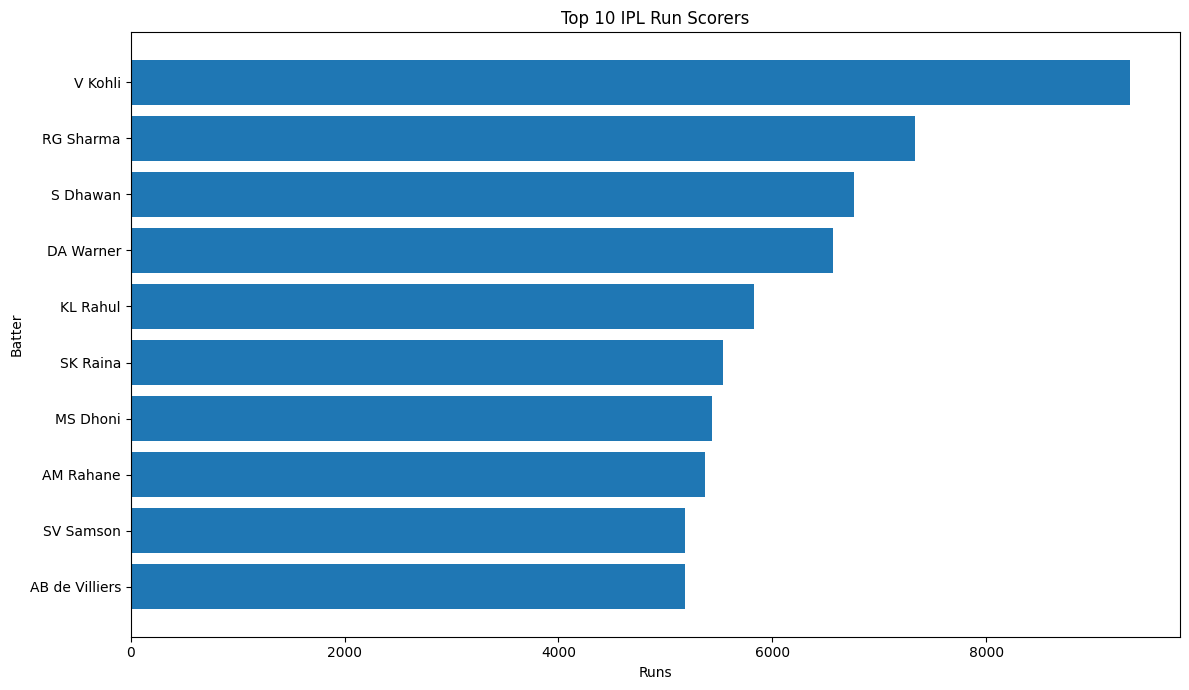

In [9]:
top_10_runs = (
    batting_summary.nlargest(10, "runs")
    .sort_values("runs")
)

plt.figure(figsize=(12, 7))
plt.barh(top_10_runs["striker"], top_10_runs["runs"])
plt.title("Top 10 IPL Run Scorers")
plt.xlabel("Runs")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()

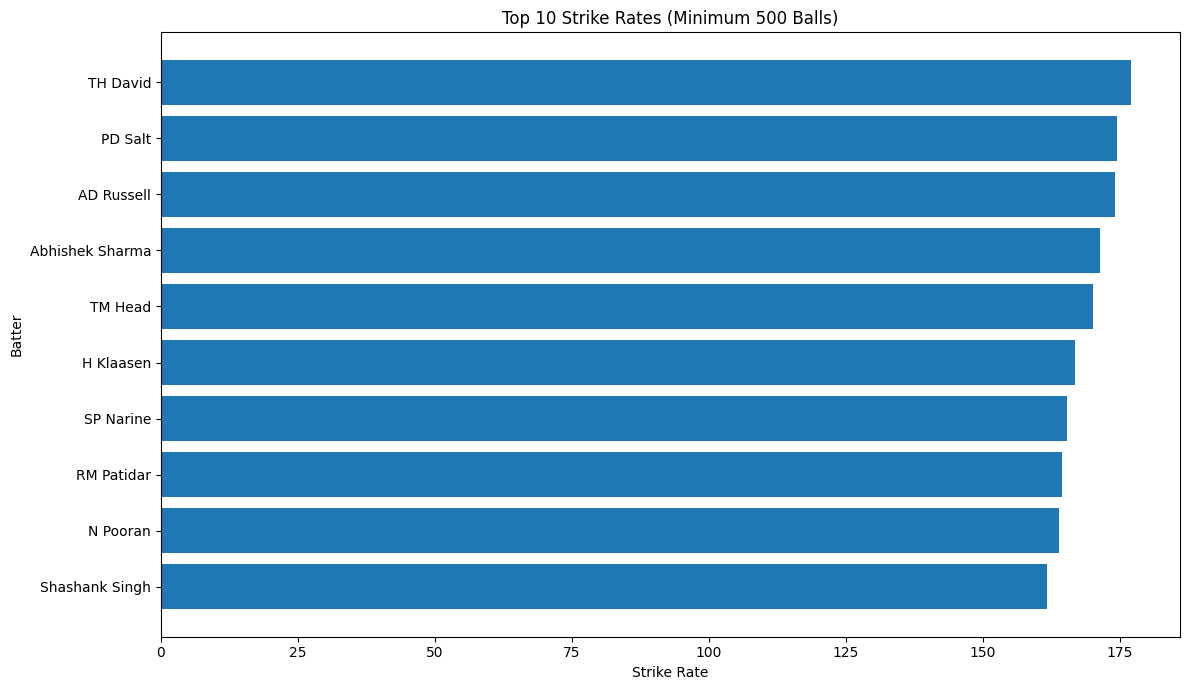

In [10]:
MIN_BALLS_FOR_STRIKE_RATE = 500

top_10_strike_rate = (
    batting_summary[
        batting_summary["balls_faced"] >= MIN_BALLS_FOR_STRIKE_RATE
    ]
    .nlargest(10, "strike_rate")
    .sort_values("strike_rate")
)

plt.figure(figsize=(12, 7))
plt.barh(
    top_10_strike_rate["striker"],
    top_10_strike_rate["strike_rate"]
)
plt.title(
    f"Top 10 Strike Rates (Minimum {MIN_BALLS_FOR_STRIKE_RATE} Balls)"
)
plt.xlabel("Strike Rate")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()

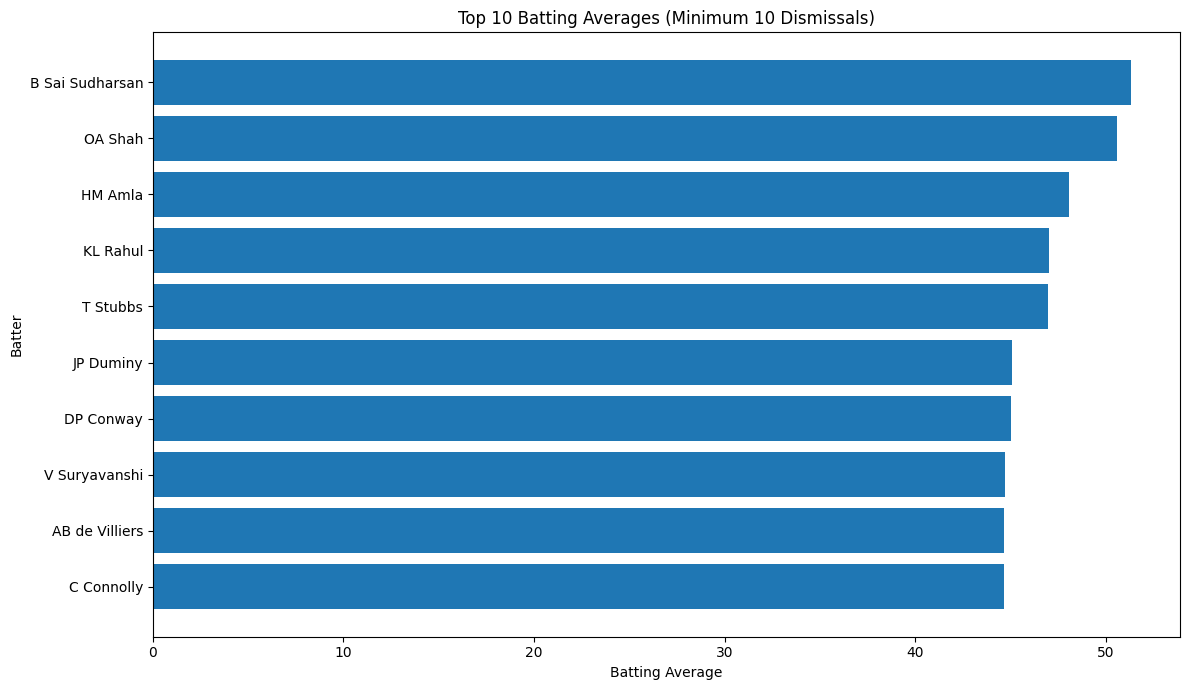

In [11]:
MIN_DISMISSALS_FOR_AVERAGE = 10

top_10_average = (
    batting_summary[
        batting_summary["dismissals"] >= MIN_DISMISSALS_FOR_AVERAGE
    ]
    .nlargest(10, "batting_average")
    .sort_values("batting_average")
)

plt.figure(figsize=(12, 7))
plt.barh(
    top_10_average["striker"],
    top_10_average["batting_average"]
)
plt.title(
    f"Top 10 Batting Averages (Minimum {MIN_DISMISSALS_FOR_AVERAGE} Dismissals)"
)
plt.xlabel("Batting Average")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()

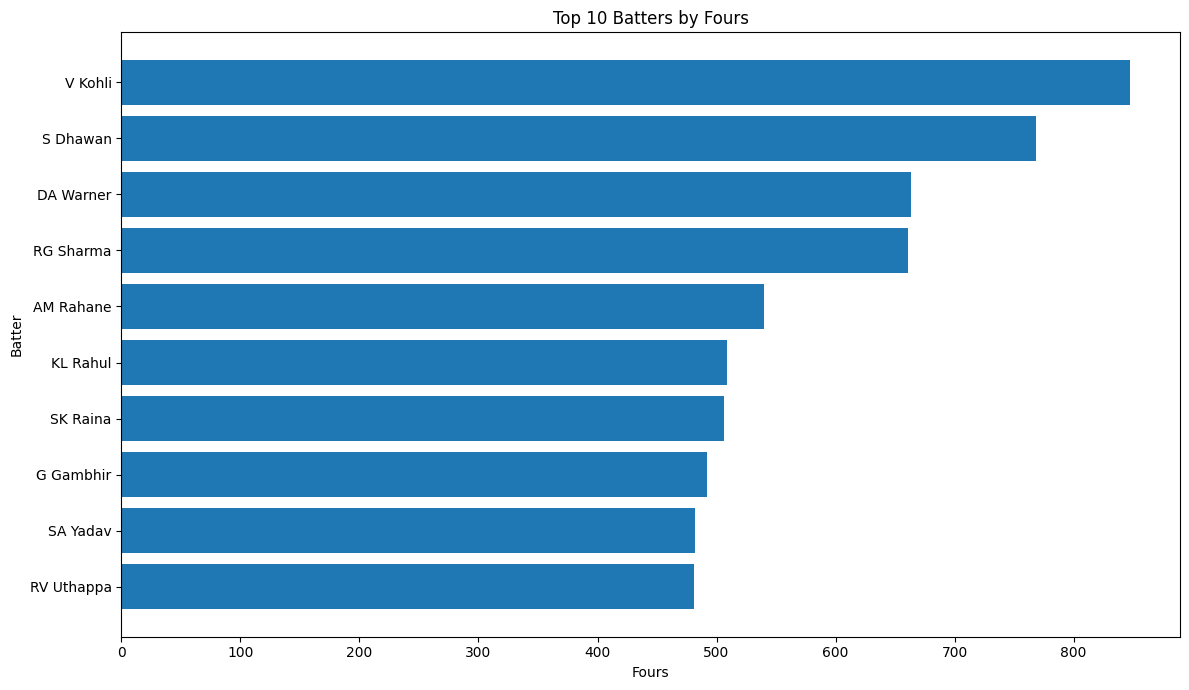

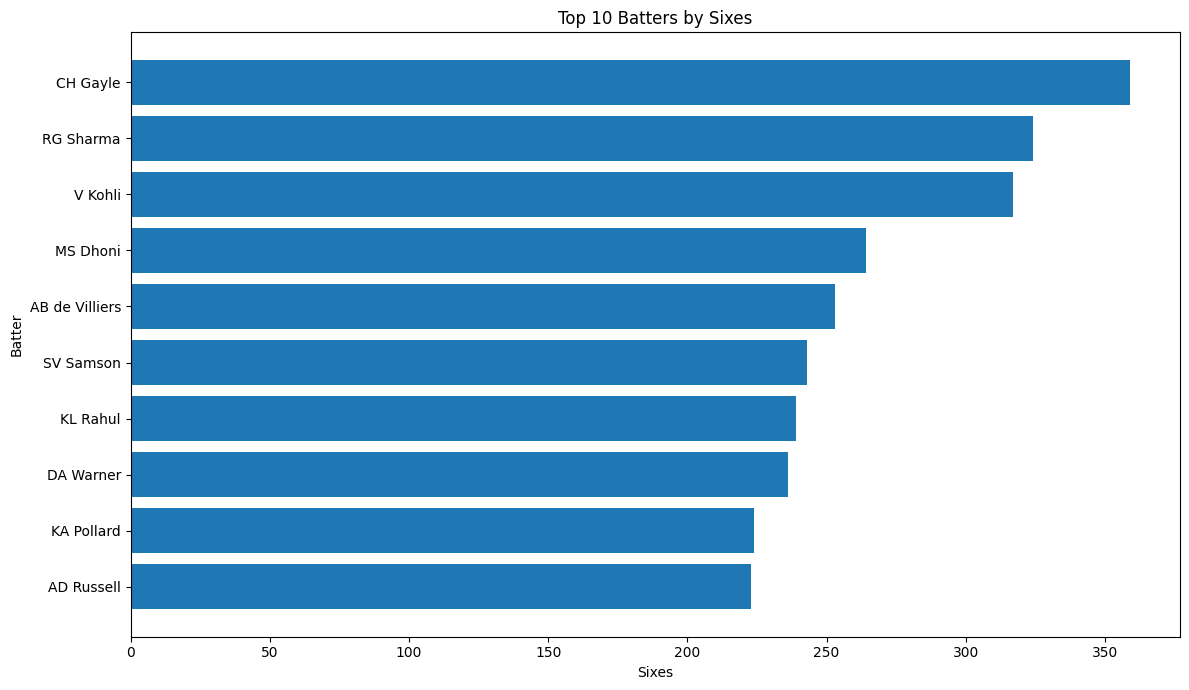

In [12]:
top_fours = (
    batting_summary.nlargest(10, "fours")
    .sort_values("fours")
)

plt.figure(figsize=(12, 7))
plt.barh(top_fours["striker"], top_fours["fours"])
plt.title("Top 10 Batters by Fours")
plt.xlabel("Fours")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()

top_sixes = (
    batting_summary.nlargest(10, "sixes")
    .sort_values("sixes")
)

plt.figure(figsize=(12, 7))
plt.barh(top_sixes["striker"], top_sixes["sixes"])
plt.title("Top 10 Batters by Sixes")
plt.xlabel("Sixes")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()

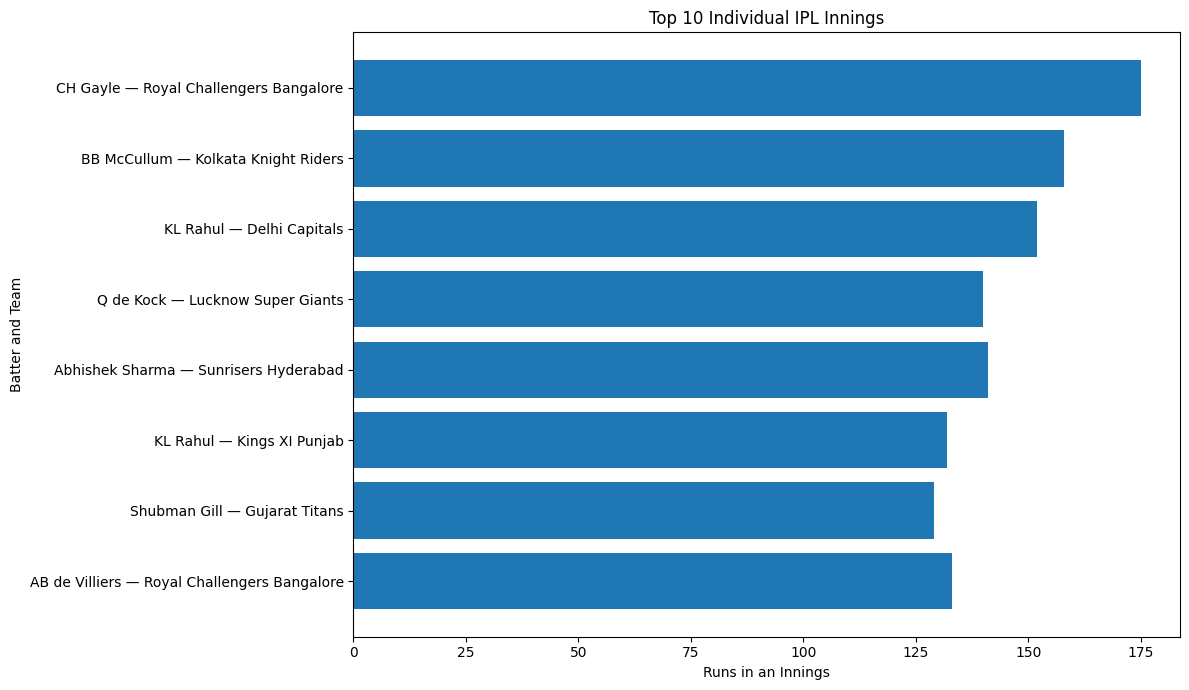

,match_id,innings,batting_team,striker,season,runs,balls_faced
5315,598027,1,Royal Challengers Bangalore,CH Gayle,2013.0,175,66
0,335982,1,Kolkata Knight Riders,BB McCullum,NaN,158,73
18243,1529278,1,Delhi Capitals,KL Rahul,2026.0,152,67
17008,1473464,2,Sunrisers Hyderabad,Abhishek Sharma,2025.0,141,55
14171,1304112,1,Lucknow Super Giants,Q de Kock,2022.0,140,70
18178,1529274,1,Sunrisers Hyderabad,Abhishek Sharma,2026.0,135,68
7556,829795,1,Royal Challengers Bangalore,AB de Villiers,2015.0,133,59
11623,1216510,1,Kings XI Punjab,KL Rahul,NaN,132,69
15441,1370352,1,Gujarat Titans,Shubman Gill,2023.0,129,60
8387,980987,1,Royal Challengers Bangalore,AB de Villiers,2016.0,129,52


In [13]:
top_individual_scores = (
    innings_scores.sort_values(
        ["runs", "balls_faced"], ascending=[False, False]
    )
    .head(10)
)

plt.figure(figsize=(12, 7))

labels = (
    top_individual_scores["striker"].astype(str)
    + " — "
    + top_individual_scores["batting_team"].astype(str)
)

plt.barh(labels.iloc[::-1], top_individual_scores["runs"].iloc[::-1])
plt.title("Top 10 Individual IPL Innings")
plt.xlabel("Runs in an Innings")
plt.ylabel("Batter and Team")
plt.tight_layout()
plt.show()

display(top_individual_scores)

In [14]:
season_batting = (
    valid_batting.groupby(["season", "striker"], dropna=False)
    .agg(
        runs=("runs_off_bat", "sum"),
        balls_faced=("ball_faced", "sum"),
        matches=("match_id", "nunique")
    )
    .reset_index()
)

season_batting["strike_rate"] = np.where(
    season_batting["balls_faced"] > 0,
    season_batting["runs"] / season_batting["balls_faced"] * 100,
    np.nan
)

top_batter_per_season = (
    season_batting.sort_values(
        ["season", "runs"], ascending=[True, False]
    )
    .groupby("season", dropna=False)
    .head(1)
    .sort_values("season")
)

display(top_batter_per_season)

,season,striker,runs,balls_faced,matches,strike_rate
75,2009.0,ML Hayden,572,395,12,144.810127
184,2011.0,CH Gayle,608,332,12,183.132530
366,2012.0,CH Gayle,733,456,14,160.745614
592,2013.0,MEK Hussey,733,566,17,129.505300
770,2014.0,RV Uthappa,660,479,16,137.787056
830,2015.0,DA Warner,562,359,14,156.545961
1065,2016.0,V Kohli,973,640,16,152.031250
1104,2017.0,DA Warner,641,452,14,141.814159
1276,2018.0,KS Williamson,735,516,17,142.441860
1376,2019.0,DA Warner,692,481,12,143.866944


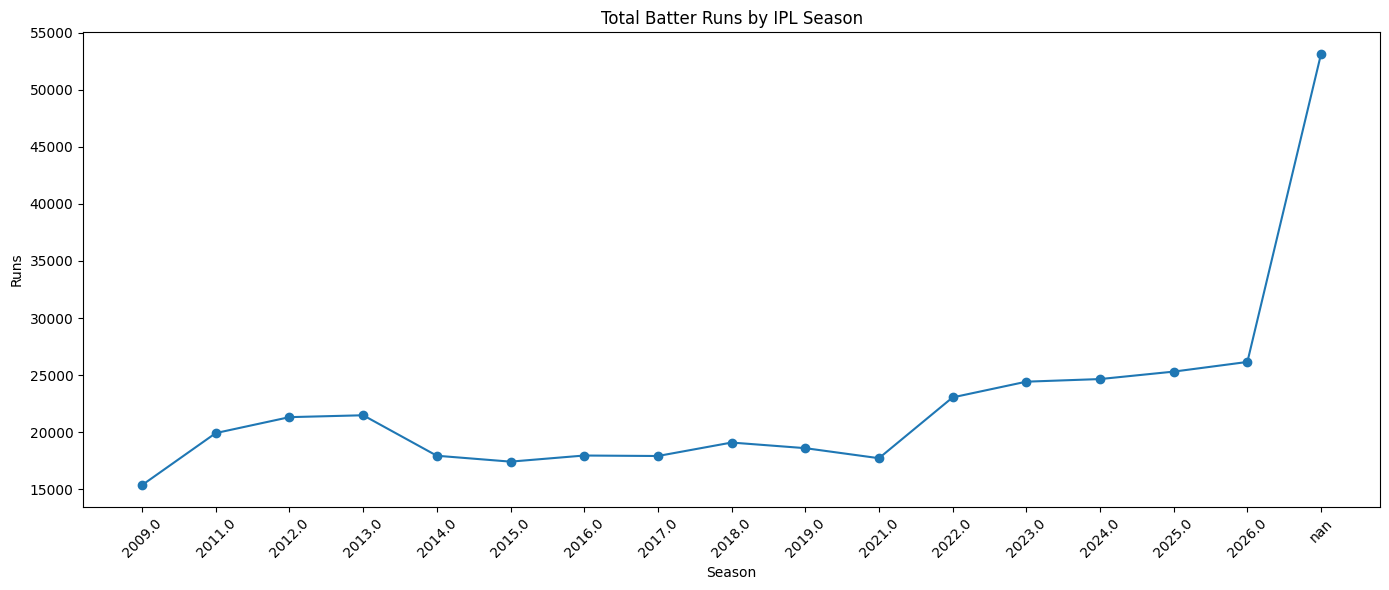

In [15]:
season_runs = (
    valid_batting.groupby("season", dropna=False)["runs_off_bat"]
    .sum()
    .reset_index(name="total_batter_runs")
    .sort_values("season")
)

plt.figure(figsize=(14, 6))
plt.plot(
    season_runs["season"].astype(str),
    season_runs["total_batter_runs"],
    marker="o"
)
plt.title("Total Batter Runs by IPL Season")
plt.xlabel("Season")
plt.ylabel("Runs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,batting_team,batter_runs,matches,unique_batters
10,Mumbai Indians,45203,291,149
0,Chennai Super Kings,41444,265,95
8,Kolkata Knight Riders,41248,278,135
13,Rajasthan Royals,38532,250,160
16,Royal Challengers Bangalore,35810,240,144
18,Sunrisers Hyderabad,32920,210,115
6,Kings XI Punjab,28541,190,114
3,Delhi Daredevils,23022,161,100
2,Delhi Capitals,19051,119,84
12,Punjab Kings,14751,87,61


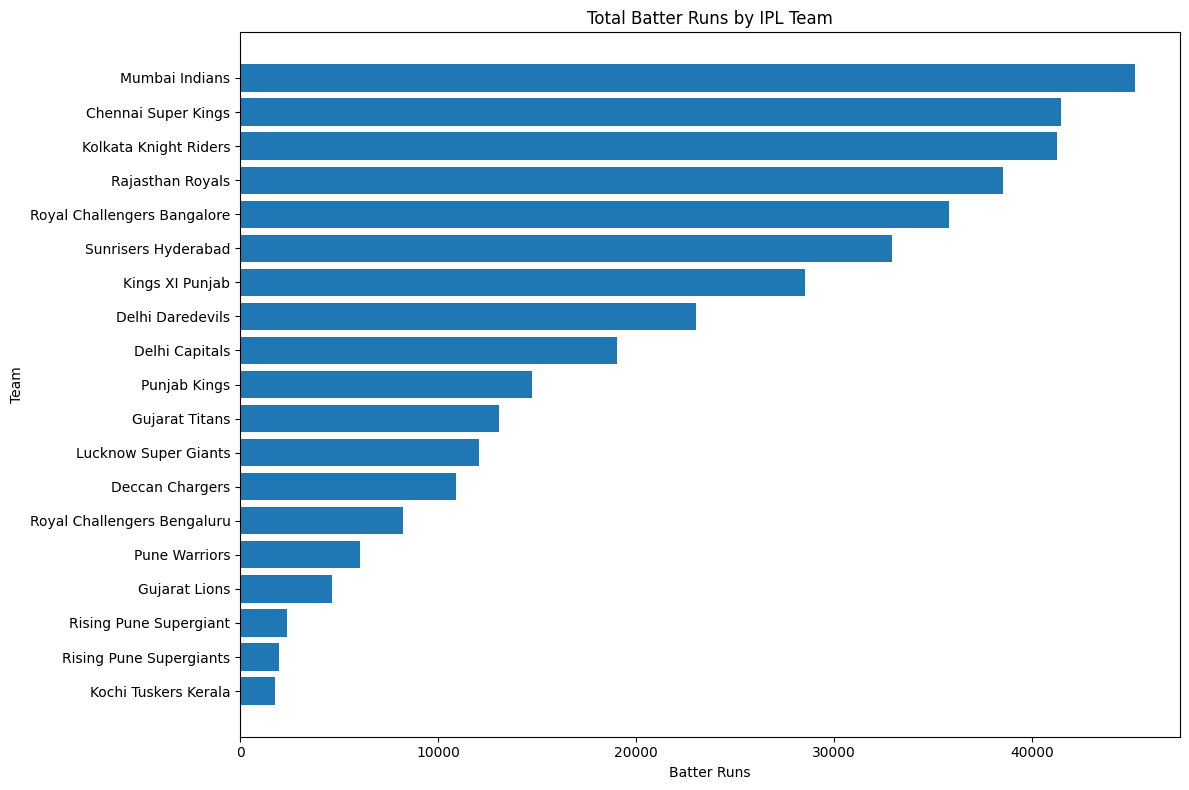

In [16]:
team_batting = (
    valid_batting.groupby("batting_team")
    .agg(
        batter_runs=("runs_off_bat", "sum"),
        matches=("match_id", "nunique"),
        unique_batters=("striker", "nunique")
    )
    .reset_index()
    .sort_values("batter_runs", ascending=False)
)

display(team_batting)

team_plot = team_batting.sort_values("batter_runs")

plt.figure(figsize=(12, 8))
plt.barh(team_plot["batting_team"], team_plot["batter_runs"])
plt.title("Total Batter Runs by IPL Team")
plt.xlabel("Batter Runs")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

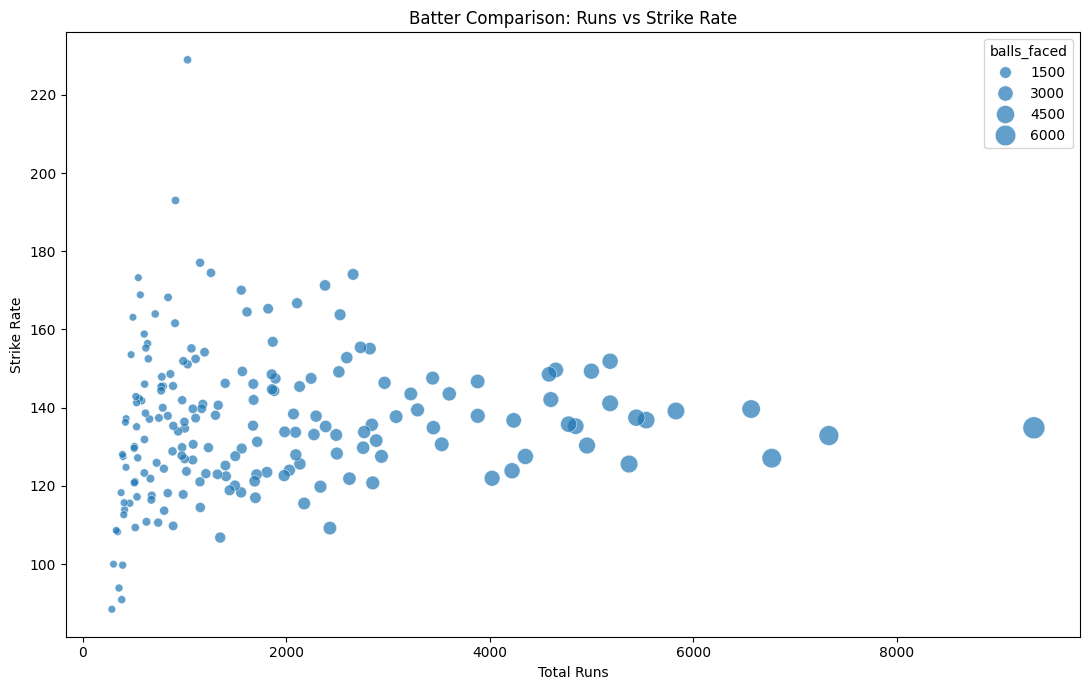

In [17]:
comparison_df = batting_summary[
    (batting_summary["balls_faced"] >= 300)
    & (batting_summary["runs"] > 0)
].copy()

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=comparison_df,
    x="runs",
    y="strike_rate",
    size="balls_faced",
    sizes=(30, 250),
    alpha=0.7
)

plt.title("Batter Comparison: Runs vs Strike Rate")
plt.xlabel("Total Runs")
plt.ylabel("Strike Rate")
plt.tight_layout()
plt.show()

In [18]:
print("BATTTING ANALYSIS VALIDATION")
print("-" * 40)

print("Number of batters:", batting_summary["striker"].nunique())
print("Total batter runs:", int(batting_summary["runs"].sum()))
print("Total fours:", int(batting_summary["fours"].sum()))
print("Total sixes:", int(batting_summary["sixes"].sum()))
print("Total balls faced:", int(batting_summary["balls_faced"].sum()))

print(
    "Batting averages available:",
    int(batting_summary["batting_average"].notna().sum())
)

print(
    "Highest individual score:",
    innings_scores["runs"].max()
)

print(
    "Number of seasons:",
    valid_batting["season"].nunique()
)

# Basic consistency checks
assert (batting_summary["runs"] >= 0).all()
assert (batting_summary["balls_faced"] >= 0).all()
assert (batting_summary["fours"] >= 0).all()
assert (batting_summary["sixes"] >= 0).all()

print("\nBasic validation checks passed.")

BATTTING ANALYSIS VALIDATION
----------------------------------------
Number of batters: 739
Total batter runs: 381529
Total fours: 34447
Total sixes: 15779
Total balls faced: 285856
Batting averages available: 667
Highest individual score: 175
Number of seasons: 16

Basic validation checks passed.


In [19]:
batting_summary.to_csv(
    OUTPUT_DIR / "batter_career_statistics.csv",
    index=False
)

innings_scores.to_csv(
    OUTPUT_DIR / "individual_innings_scores.csv",
    index=False
)

season_batting.to_csv(
    OUTPUT_DIR / "season_batting_statistics.csv",
    index=False
)

top_batter_per_season.to_csv(
    OUTPUT_DIR / "top_batter_per_season.csv",
    index=False
)

team_batting.to_csv(
    OUTPUT_DIR / "team_batting_statistics.csv",
    index=False
)

season_runs.to_csv(
    OUTPUT_DIR / "season_total_batter_runs.csv",
    index=False
)

print("Batting analysis exports completed.")
print("Files saved to:", OUTPUT_DIR)

for file_path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(file_path.name)

Batting analysis exports completed.
Files saved to: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\BATTING
batter_career_statistics.csv
individual_innings_scores.csv
season_batting_statistics.csv
season_total_batter_runs.csv
team_batting_statistics.csv
top_batter_per_season.csv


In [20]:
leaderboard_columns = [
    "striker",
    "runs",
    "matches",
    "innings",
    "dismissals",
    "batting_average",
    "balls_faced",
    "strike_rate",
    "fours",
    "sixes",
    "highest_score"
]

display(
    batting_summary[leaderboard_columns]
    .sort_values("runs", ascending=False)
    .head(25)
    .round(2)
)

,striker,runs,matches,innings,dismissals,batting_average,balls_faced,strike_rate,fours,sixes,highest_score
0,V Kohli,9346,275,277,222,42.10,6930,134.86,847,317,113
1,RG Sharma,7331,275,276,234,31.33,5517,132.88,661,324,109
2,S Dhawan,6769,221,222,176,38.46,5326,127.09,768,153,106
3,DA Warner,6567,184,187,154,42.64,4702,139.66,663,236,126
4,KL Rahul,5828,149,152,124,47.00,4188,139.16,509,239,152
5,SK Raina,5536,200,201,156,35.49,4046,136.83,506,204,100
6,MS Dhoni,5439,241,241,132,41.20,3957,137.45,375,264,84
7,AM Rahane,5367,197,197,170,31.57,4273,125.60,540,141,105
9,AB de Villiers,5181,170,172,116,44.66,3411,151.89,414,253,133
8,SV Samson,5181,185,185,154,33.64,3671,141.13,432,243,119
